# Stage 3 — Exploratory Data Analysis

**Notebook 3 of 6** · Governed by `DOCS/STRUCTURE.md` Stage 3

---

## What this notebook is for

Hypothesis-driven exploration of the **302 distinct patients** produced by Stage 2. Not an
open-ended tour: every section maps to one branch of the Stage 0 issue tree, every chart carries
an **Action Title**, and every finding is followed by a written **So What / Implication**.

### The issue tree being tested

```
What distinguishes patients with angiographic heart disease in this cohort?
│
├── A. Demographics             → age, sex
├── B. Symptom presentation     → cp
├── C. Resting clinical status  → trestbps, chol, fbs, restecg
├── D. Exercise-stress response → thalach, exang, oldpeak, slope
└── E. Imaging / angiographic   → ca, thal      ⚠ SCOPE 2 ONLY — same procedure as the label
```

**Prior hypothesis (Stage 0):** branch **D** carries the largest non-tautological signal; branch
**C** — the resting measurements patients are actually counselled about — is close to a null.

Statistical *verdicts* with effect sizes, confidence intervals and FDR correction are Stage 5a's
job (`04_diagnostic.ipynb`). This notebook establishes shape, direction, and data quality.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import roc_auc_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ROOT = Path.cwd() if (Path.cwd() / "heart.csv").exists() else Path.cwd().parent
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)

# --- DOCS/DESIGN.md palette, inline (no local imports)
NAVY, BLUE, TEAL = "#051C2C", "#2251FF", "#00857C"
CYAN, AMBER = "#00A9F4", "#C1841C"
SLATE, GREY, GRID = "#7F93A6", "#9FADB8", "#E9ECEF"
C_DISEASE, C_NODISEASE, C_CONTEXT, C_REF = BLUE, TEAL, GREY, AMBER


def apply_mck_style():
    mpl.rcParams.update({
        "figure.facecolor": "white", "axes.facecolor": "white",
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"], "font.size": 9.5,
        "text.color": NAVY, "axes.labelcolor": NAVY, "axes.labelsize": 9,
        "axes.edgecolor": GRID, "axes.linewidth": 0.9,
        "xtick.color": SLATE, "ytick.color": SLATE,
        "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
        "xtick.major.size": 0, "ytick.major.size": 0,
        "axes.titlelocation": "left", "axes.titlesize": 10, "axes.titleweight": "bold",
        "axes.titlepad": 10, "axes.titlecolor": NAVY,
        "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
        "legend.frameon": False, "legend.fontsize": 8.5,
        "figure.dpi": 110, "savefig.dpi": 200,
        "savefig.bbox": "tight", "savefig.facecolor": "white",
    })


apply_mck_style()


def save_exhibit(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    print(f"saved reports/figures/{name}.png")


def source_note(fig, text, y=-0.05):
    fig.text(0.02, y, text, fontsize=7.5, color=SLATE, ha="left")


df = pd.read_parquet(ROOT / "data" / "processed" / "heart_clean.parquet")

NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak"]
BINARY = ["sex", "fbs", "exang"]
NOMINAL = ["cp", "restecg", "thal"]
ORDINAL = ["slope", "ca"]
BRANCH = {"age": "A", "sex": "A", "cp": "B",
          "trestbps": "C", "chol": "C", "fbs": "C", "restecg": "C",
          "thalach": "D", "exang": "D", "oldpeak": "D", "slope": "D",
          "ca": "E", "thal": "E"}
BRANCH_NAME = {"A": "A · Demographics", "B": "B · Symptom presentation",
               "C": "C · Resting clinical", "D": "D · Exercise-stress response",
               "E": "E · Angiographic (Scope 2)"}

print(f"{len(df)} distinct patients x {df.shape[1]} columns "
      f"({df['target'].sum()} disease / {(1 - df['target']).sum()} no disease)")

302 distinct patients x 16 columns (164 disease / 138 no disease)


## 3.1 First-pass profile

`ydata-profiling` is not a pinned dependency — the manual panel below covers the same ground
(central tendency, dispersion, shape, missingness) and keeps a clone runnable on the pinned set.

In [2]:
profile = df[NUMERIC].describe().T
profile["skew"] = df[NUMERIC].skew()
profile["kurtosis"] = df[NUMERIC].kurtosis()
profile["nulls"] = df[NUMERIC].isna().sum()
profile["branch"] = [BRANCH[c] for c in NUMERIC]
display(profile.round(2))

cat_profile = pd.DataFrame({
    "branch": [BRANCH[c] for c in BINARY + NOMINAL + ORDINAL],
    "type": (["binary"] * len(BINARY) + ["nominal"] * len(NOMINAL) + ["ordinal"] * len(ORDINAL)),
    "levels": [int(df[c].nunique(dropna=True)) for c in BINARY + NOMINAL + ORDINAL],
    "nulls": [int(df[c].isna().sum()) for c in BINARY + NOMINAL + ORDINAL],
    "modal_share": [f"{df[c].value_counts(normalize=True).iloc[0]:.0%}"
                    for c in BINARY + NOMINAL + ORDINAL],
}, index=BINARY + NOMINAL + ORDINAL)
cat_profile

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,nulls,branch
age,302.0,54.42,9.05,29.0,48.00,55.5,61.00,77.0,-0.20,-0.53,0,A
trestbps,302.0,131.60,17.56,94.0,120.00,130.0,140.00,200.0,0.72,0.92,0,C
chol,302.0,246.50,51.75,126.0,211.00,240.5,274.75,564.0,1.15,4.54,0,C
thalach,302.0,149.57,22.90,71.0,133.25,152.5,166.00,202.0,-0.53,-0.06,0,D
oldpeak,302.0,1.04,1.16,0.0,0.00,0.8,1.60,6.2,1.27,1.57,0,D


,branch,type,levels,nulls,modal_share
sex,A,binary,2,0,68%
fbs,C,binary,2,0,85%
exang,D,binary,2,0,67%
cp,B,nominal,4,0,47%
restecg,C,nominal,3,0,50%
thal,E,nominal,3,2,55%
slope,D,ordinal,3,0,47%
ca,E,ordinal,4,4,59%


**Shape notes carried into modelling:**

- **Scale disparity is large** — `chol` spans 126–564 while `oldpeak` spans 0–6.2.
  Standardisation is mandatory for the logistic, SVM and k-NN paths.
- **`oldpeak` is the most skewed** (≈ +1.2) and 32% zero-inflated — a genuine flat ST response,
  not missingness. Favours tree splits over a single linear term.
- **`restecg` level 2 has only 4 patients** — too thin to support a stable one-hot coefficient.
  Flagged now; revisited when χ² expected-cell counts are checked in Stage 5a.
- Only the 6 deliberate `ca`/`thal` nulls from Stage 2 remain.

## 3.2 Cohort composition — who is actually in this dataset

Before asking what separates the classes, establish **who was sampled**. This determines what the
54.3% positive rate means and sets up the mandatory fairness audit.

In [3]:
comp = pd.crosstab(df["sex"].map({0: "Female", 1: "Male"}), df["target"],
                   margins=True, margins_name="All")
comp.columns = ["no disease", "disease", "all"]
comp["disease rate"] = (comp["disease"] / comp["all"]).map("{:.1%}".format)
comp["share of cohort"] = (comp["all"] / len(df)).map("{:.1%}".format)
display(comp)

print(f"age: {df['age'].min():.0f}-{df['age'].max():.0f}, "
      f"mean {df['age'].mean():.1f} (SD {df['age'].std():.1f})")
print(f"disease patients are on average {df.loc[df.target == 0, 'age'].mean() - df.loc[df.target == 1, 'age'].mean():.1f} "
      "years YOUNGER than non-disease patients")

,no disease,disease,all,disease rate,share of cohort
sex,,,,,
Female,24,72,96,75.0%,31.8%
Male,114,92,206,44.7%,68.2%
All,138,164,302,54.3%,100.0%


age: 29-77, mean 54.4 (SD 9.0)
disease patients are on average 4.0 years YOUNGER than non-disease patients


saved reports/figures/ex02_cohort.png


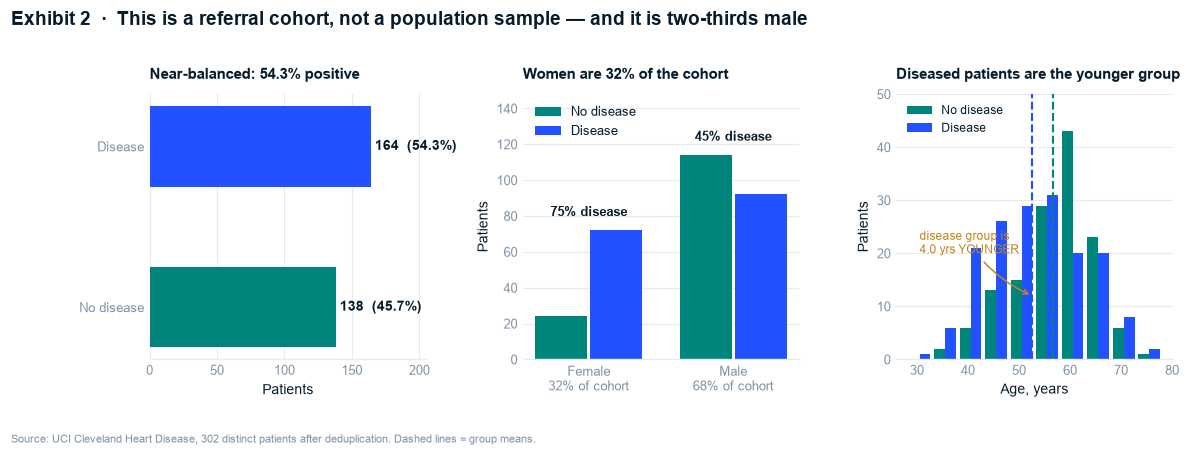

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
fig.subplots_adjust(wspace=0.35, top=0.78)

# Panel 1 - outcome balance
ax = axes[0]
vc = df["target"].value_counts().sort_index()
bars = ax.barh(["No disease", "Disease"], vc.values, color=[C_NODISEASE, C_DISEASE], height=0.5)
for b, v in zip(bars, vc.values):
    ax.text(v + 3, b.get_y() + b.get_height() / 2, f"{v}  ({v/len(df):.1%})",
            va="center", fontsize=9, color=NAVY, fontweight="bold")
ax.set_title("Near-balanced: 54.3% positive")
ax.set_xlim(0, 205)
ax.set_xlabel("Patients")
ax.grid(axis="y", visible=False)

# Panel 2 - sex composition and disease rate
ax = axes[1]
sex_ct = pd.crosstab(df["sex"], df["target"])
x = np.arange(2)
ax.bar(x - 0.19, sex_ct[0].values, width=0.36, color=C_NODISEASE, label="No disease")
ax.bar(x + 0.19, sex_ct[1].values, width=0.36, color=C_DISEASE, label="Disease")
for i in x:
    rate = sex_ct.loc[i, 1] / sex_ct.loc[i].sum()
    ax.text(i, max(sex_ct.loc[i]) + 8, f"{rate:.0%} disease", ha="center",
            fontsize=8.5, color=NAVY, fontweight="bold")
ax.set_xticks(x, [f"Female\n{96/len(df):.0%} of cohort", f"Male\n{206/len(df):.0%} of cohort"])
ax.set_title("Women are 32% of the cohort")
ax.set_ylabel("Patients")
ax.set_ylim(0, 148)
ax.legend(loc="upper left", ncols=1)
ax.grid(axis="x", visible=False)

# Panel 3 - age distribution by outcome
ax = axes[2]
bins = np.arange(28, 80, 5)
ax.hist([df.loc[df.target == 0, "age"], df.loc[df.target == 1, "age"]], bins=bins,
        color=[C_NODISEASE, C_DISEASE], label=["No disease", "Disease"], rwidth=0.85)
ax.axvline(df.loc[df.target == 1, "age"].mean(), color=C_DISEASE, ls="--", lw=1.4)
ax.axvline(df.loc[df.target == 0, "age"].mean(), color=C_NODISEASE, ls="--", lw=1.4)
ax.annotate("disease group is\n4.0 yrs YOUNGER", xy=(52.6, 12), xytext=(30.5, 20),
            fontsize=8, color=AMBER,
            arrowprops=dict(arrowstyle="->", color=AMBER, lw=1,
                            connectionstyle="arc3,rad=0.15"))
ax.set_title("Diseased patients are the younger group")
ax.set_xlabel("Age, years")
ax.set_ylabel("Patients")
ax.set_ylim(0, 50)
ax.legend(loc="upper left", fontsize=8)
ax.grid(axis="x", visible=False)

fig.suptitle("Exhibit 2  ·  This is a referral cohort, not a population sample — and it is two-thirds male",
             x=0.02, ha="left", fontsize=12.5, fontweight="bold", color=NAVY, y=0.99)
source_note(fig, "Source: UCI Cleveland Heart Disease, 302 distinct patients after deduplication. "
                 "Dashed lines = group means.", y=-0.10)
save_exhibit(fig, "ex02_cohort")
plt.show()

### Finding — two properties that constrain every downstream claim

**1. Disease patients are *younger*, not older (52.6 vs 56.6 years).** Age is a well-established
cardiac risk factor, so a cohort where the diseased are younger is not a general population — it
is a **referral filter**. Older patients were sent for angiography and came back clean; younger
patients had to present with something more alarming to be referred at all.

> **So What:** the 54.3% positive rate describes *who was referred for catheterisation*, not
> prevalence in any population. Every association found here is conditional on referral.
>
> **Implication:** the report must state this on page one. Any "X% of people with trait Y have
> heart disease" reading of these results is invalid, and the inverted age effect is the
> cleanest available proof of it.

**2. Women are 32% of the cohort (96 of 302) but have a 75% disease rate versus 45% for men.**
The same referral filter, applied harder: a woman had to look considerably sicker to be sent for
angiography.

> **So What:** the protected attribute is both under-represented *and* differently distributed
> with respect to the outcome — the classic setup for a model that works well on the majority
> group and quietly fails the minority one.
>
> **Implication:** the Stage 6 subgroup fairness audit is mandatory, and at n = 96 women its
> confidence intervals will be wide. That width is a finding to report, not a reason to skip it.

## 3.3 Branches A, C, D — how the numeric measurements separate

One panel per continuous feature, split by outcome, ordered by separation strength. Cohen's *d*
and single-feature AUC are shown as orientation; Stage 5a supplies confidence intervals and FDR
correction.

In [5]:
rows = []
for c in NUMERIC:
    a, b = df.loc[df.target == 1, c], df.loc[df.target == 0, c]
    n1, n0 = len(a), len(b)
    sp = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n0 - 1) * b.var(ddof=1)) / (n1 + n0 - 2))
    d_val = (a.mean() - b.mean()) / sp
    auc = roc_auc_score(df["target"], df[c])
    rows.append({
        "feature": c, "branch": BRANCH[c],
        "disease_mean": a.mean(), "no_disease_mean": b.mean(),
        "cohens_d": d_val, "abs_d": abs(d_val),
        "univariate_auc": max(auc, 1 - auc),
        "welch_p": stats.ttest_ind(a, b, equal_var=False).pvalue,
    })
numeric_sep = pd.DataFrame(rows).sort_values("abs_d", ascending=False).reset_index(drop=True)
display(numeric_sep.drop(columns="abs_d").round(3))

,feature,branch,disease_mean,no_disease_mean,cohens_d,univariate_auc,welch_p
0,oldpeak,D,0.587,1.586,-0.951,0.739,0.000
1,thalach,D,158.378,139.101,0.926,0.747,0.000
2,age,A,52.585,56.601,-0.454,0.636,0.000
3,trestbps,C,129.250,134.399,-0.296,0.571,0.012
4,chol,C,242.640,251.087,-0.163,0.568,0.155


saved reports/figures/ex03_numeric_distributions.png


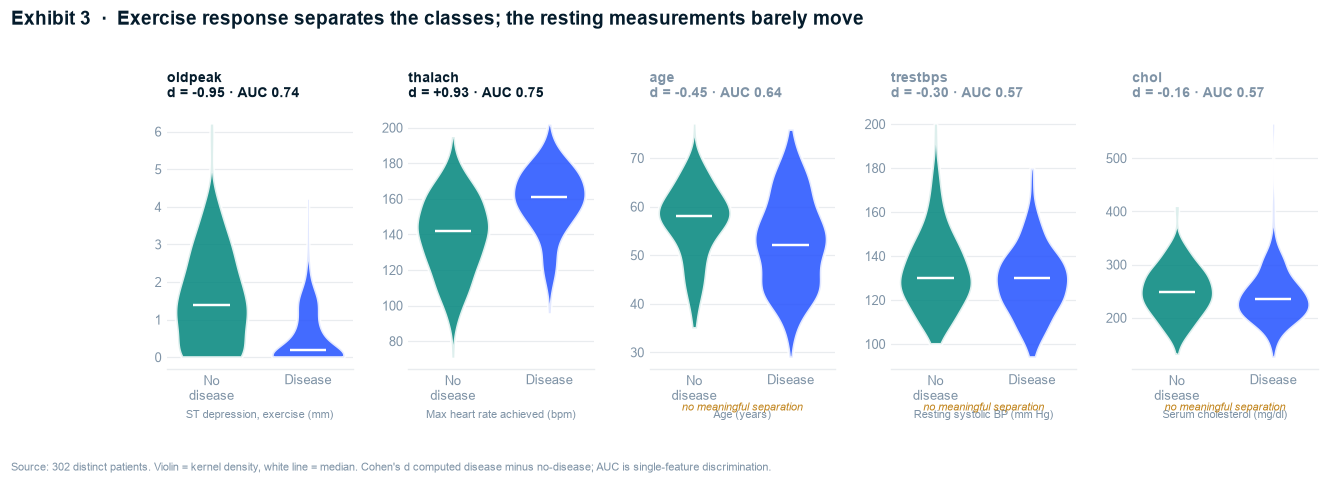

In [6]:
order = numeric_sep["feature"].tolist()
LABELS = {"thalach": "Max heart rate achieved (bpm)", "oldpeak": "ST depression, exercise (mm)",
          "age": "Age (years)", "trestbps": "Resting systolic BP (mm Hg)",
          "chol": "Serum cholesterol (mg/dl)"}

fig, axes = plt.subplots(1, 5, figsize=(13.5, 3.7))
fig.subplots_adjust(wspace=0.30, top=0.74)

for ax, c in zip(axes, order):
    r = numeric_sep.set_index("feature").loc[c]
    parts = ax.violinplot([df.loc[df.target == 0, c].dropna(), df.loc[df.target == 1, c].dropna()],
                          positions=[0, 1], widths=0.75, showextrema=False, showmedians=True)
    for pc, col in zip(parts["bodies"], [C_NODISEASE, C_DISEASE]):
        pc.set_facecolor(col)
        pc.set_alpha(0.85)
        pc.set_edgecolor("white")
        pc.set_linewidth(2)
    parts["cmedians"].set_color("white")
    parts["cmedians"].set_linewidth(1.6)
    strong = r["abs_d"] >= 0.5
    ax.set_title(f"{c}\nd = {r['cohens_d']:+.2f} · AUC {r['univariate_auc']:.2f}",
                 fontsize=9, color=NAVY if strong else SLATE)
    ax.set_xticks([0, 1], ["No\ndisease", "Disease"])
    ax.set_xlabel(LABELS[c], fontsize=7.5, color=SLATE)
    ax.grid(axis="x", visible=False)
    if not strong:
        ax.text(0.5, -0.13, "no meaningful separation", transform=ax.transAxes, ha="center",
                va="top", fontsize=7.5, color=AMBER, style="italic")

fig.suptitle("Exhibit 3  ·  Exercise response separates the classes; the resting measurements barely move",
             x=0.02, ha="left", fontsize=12.5, fontweight="bold", color=NAVY, y=0.99)
source_note(fig, "Source: 302 distinct patients. Violin = kernel density, white line = median. "
                 "Cohen's d computed disease minus no-disease; AUC is single-feature discrimination.",
            y=-0.14)
save_exhibit(fig, "ex03_numeric_distributions")
plt.show()

### Finding — the two exercise variables dominate, and cholesterol does nothing

| Feature | Branch | Cohen's *d* | AUC | Reading |
|---|---|---|---|---|
| `oldpeak` (ST depression) | **D** | **−0.95** | 0.74 | Strongest numeric separator |
| `thalach` (max heart rate) | **D** | **+0.93** | 0.75 | Equally strong, opposite direction |
| `age` | A | −0.45 | 0.64 | Moderate — and inverted (§3.2) |
| `trestbps` (resting BP) | C | −0.30 | 0.57 | Weak, and the *wrong* direction |
| `chol` (cholesterol) | C | −0.16 | 0.57 | **Null — p = 0.16** |

> **So What:** the diagnostic signal lives in how the heart behaves **under stress**, not in what
> it looks like at rest. Diseased patients reach a peak heart rate ~19 bpm lower and show ~1.0 mm
> more ST depression — both large, coherent, and clinically interpretable effects.
>
> **Implication:** if a prospective triage study is ever run, the exercise-stress protocol is what
> must be captured. A resting workup alone would carry very little of this signal.

**The cholesterol null deserves to be reported, not buried.** Serum cholesterol — the single
measurement most associated with heart disease in public understanding — **does not separate
these groups** (p = 0.16), and its point estimate runs *backwards* (diseased patients average
8.5 mg/dl lower). Confirmed with a confidence interval in Stage 5a.

## 3.4 Branches B, D, E — how the categorical findings separate

Cross-tabulated as **disease rate per level**, with Cramér's V for association strength.
`cp`, `restecg` and `thal` are nominal — no mean is computed on their codes, per the Stage 2
contract.

In [7]:
CAT_ALL = BINARY + NOMINAL + ORDINAL
rows = []
for c in CAT_ALL:
    ct = pd.crosstab(df[c], df["target"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    rates = (ct[1] / ct.sum(axis=1))
    rows.append({
        "feature": c, "branch": BRANCH[c], "levels": ct.shape[0],
        "cramers_v": v, "chi2_p": p,
        "min_rate": rates.min(), "max_rate": rates.max(),
        "spread_pp": (rates.max() - rates.min()) * 100,
        "min_expected_cell": stats.chi2_contingency(ct)[3].min(),
    })
cat_sep = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
display(cat_sep.round(3))

,feature,branch,levels,cramers_v,chi2_p,min_rate,max_rate,spread_pp,min_expected_cell
0,thal,E,3,0.531,0.000,0.239,0.782,54.250,8.220
1,cp,B,4,0.518,0.000,0.273,0.820,54.727,10.510
2,ca,E,4,0.495,0.000,0.150,0.743,59.286,9.195
3,exang,D,2,0.429,0.000,0.232,0.695,46.226,45.238
4,slope,D,3,0.394,0.000,0.350,0.752,40.177,9.596
5,sex,A,2,0.276,0.000,0.447,0.750,30.340,43.868
6,restecg,C,3,0.179,0.008,0.250,0.629,37.914,1.828
7,fbs,C,2,0.017,0.761,0.511,0.549,3.753,20.563


In [8]:
for c in ["cp", "exang", "slope", "thal", "ca"]:
    ct = pd.crosstab(df[c], df["target"], dropna=False)
    ct.columns = ["no disease", "disease"]
    ct["n"] = ct.sum(axis=1)
    ct["disease rate"] = (ct["disease"] / ct["n"]).map("{:.1%}".format)
    print(f"\n--- {c}  (branch {BRANCH[c]})  Cramer's V = "
          f"{cat_sep.set_index('feature').loc[c, 'cramers_v']:.3f}")
    print(ct.to_string())


--- cp  (branch B)  Cramer's V = 0.518
    no disease  disease    n disease rate
cp                                       
0          104       39  143        27.3%
1            9       41   50        82.0%
2           18       68   86        79.1%
3            7       16   23        69.6%

--- exang  (branch D)  Cramer's V = 0.429
       no disease  disease    n disease rate
exang                                       
0              62      141  203        69.5%
1              76       23   99        23.2%

--- slope  (branch D)  Cramer's V = 0.394
       no disease  disease    n disease rate
slope                                       
0              12        9   21        42.9%
1              91       49  140        35.0%
2              35      106  141        75.2%

--- thal  (branch E)  Cramer's V = 0.531
      no disease  disease    n disease rate
thal                                       
1.0           12        6   18        33.3%
2.0           36      129  165        78.2%

saved reports/figures/ex04_categorical_rates.png


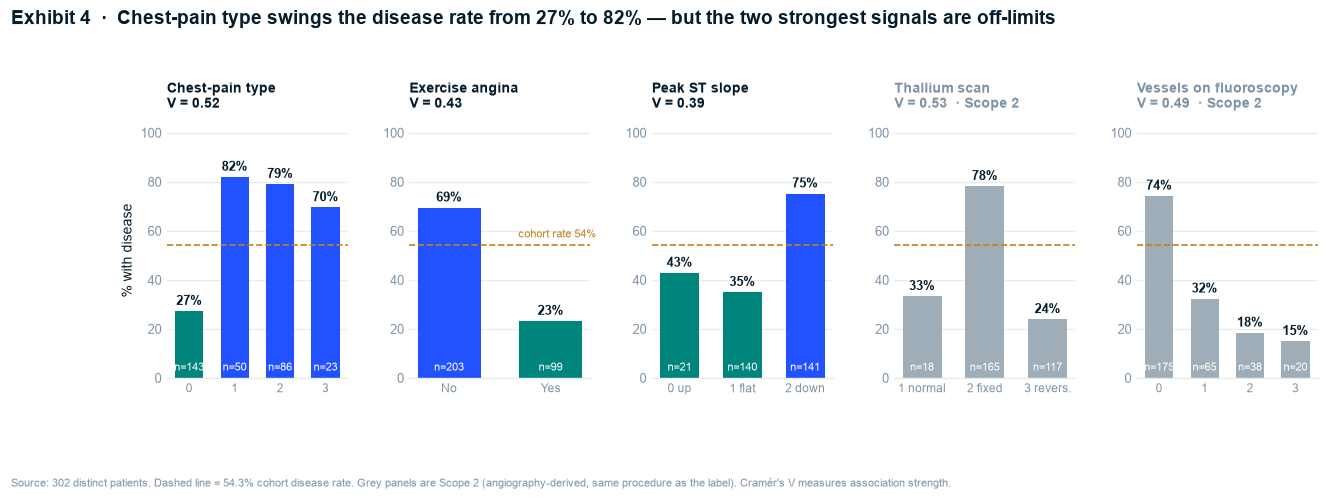

In [9]:
PANEL = [("cp", "Chest-pain type", ["0", "1", "2", "3"], "B"),
         ("exang", "Exercise angina", ["No", "Yes"], "D"),
         ("slope", "Peak ST slope", ["0 up", "1 flat", "2 down"], "D"),
         ("thal", "Thallium scan", ["1 normal", "2 fixed", "3 revers."], "E"),
         ("ca", "Vessels on fluoroscopy", ["0", "1", "2", "3"], "E")]

fig, axes = plt.subplots(1, 5, figsize=(13.5, 3.8))
fig.subplots_adjust(wspace=0.34, top=0.72)
base_rate = df["target"].mean()

for ax, (c, title, ticks, br) in zip(axes, PANEL):
    ct = pd.crosstab(df[c], df["target"])
    rates = (ct[1] / ct.sum(axis=1)) * 100
    ns = ct.sum(axis=1)
    quarantined = br == "E"
    colors = [C_CONTEXT if quarantined else (C_DISEASE if r >= base_rate * 100 else C_NODISEASE)
              for r in rates]
    bars = ax.bar(range(len(rates)), rates.values, color=colors, width=0.62)
    for i, (b, r, n) in enumerate(zip(bars, rates.values, ns.values)):
        ax.text(b.get_x() + b.get_width() / 2, r + 2.5, f"{r:.0f}%", ha="center",
                fontsize=8.5, fontweight="bold", color=NAVY)
        ax.text(b.get_x() + b.get_width() / 2, 3, f"n={n}", ha="center",
                fontsize=7, color="white")
    ax.axhline(base_rate * 100, color=C_REF, ls="--", lw=1.1, zorder=1)
    ax.set_xticks(range(len(ticks)), ticks, fontsize=8)
    ax.set_ylim(0, 104)
    ax.set_ylabel("% with disease" if c == "cp" else "")
    v = cat_sep.set_index("feature").loc[c, "cramers_v"]
    ax.set_title(f"{title}\nV = {v:.2f}" + ("  · Scope 2" if quarantined else ""),
                 fontsize=9, color=SLATE if quarantined else NAVY)
    ax.grid(axis="x", visible=False)

axes[1].text(1.45, base_rate * 100 + 3, f"cohort rate {base_rate:.0%}",
             fontsize=7.5, color=AMBER, ha="right")

fig.suptitle("Exhibit 4  ·  Chest-pain type swings the disease rate from 27% to 82% — but the two "
             "strongest signals are off-limits",
             x=0.02, ha="left", fontsize=12.5, fontweight="bold", color=NAVY, y=0.99)
source_note(fig, "Source: 302 distinct patients. Dashed line = 54.3% cohort disease rate. "
                 "Grey panels are Scope 2 (angiography-derived, same procedure as the label). "
                 "Cramér's V measures association strength.", y=-0.15)
save_exhibit(fig, "ex04_categorical_rates")
plt.show()

### Finding — and a correction to the data notes

`thal` (V = 0.53) and `ca` (V = 0.49) are the strongest associations in the dataset. **Both are
quarantined into Scope 2** — they are produced by the same catheterisation and perfusion workup
that defines the target, so their strength is largely circular. Greyed out above for that reason.

Among the features a clinician would have *before* the catheter:

- **`cp` (V = 0.52) is the strongest single predictor available.** Disease rate runs 27% at
  level 0 versus 82%, 79% and 70% at levels 1, 2 and 3.
- **`exang` (V = 0.43)** — patients *without* exercise-induced angina have a 70% disease rate;
  those *with* it, 23%. Another inversion of the naive expectation, and another fingerprint of
  the referral filter.
- **`slope` (V = 0.39)** — a downsloping peak ST segment carries a 75% disease rate against 35%
  for flat.
- **`restecg` (V = 0.18)** is weak, and its level 2 has only **4 patients** — too thin for a
  stable coefficient. Carried into Stage 5a as an expected-cell-count problem.

> **⚠ Correction to `DOCS/heart_dataset_analysis.md` §7.** The data notes propose a
> `cp_asymptomatic` feature on the rationale that *"cp == 0 (asymptomatic) is the highest-risk
> category in this encoding"*. **In this file the opposite is true:** `cp = 0` has the **lowest**
> disease rate of the four levels (27.3%). The file carries no category labels, so the semantic
> mapping cannot be verified from the data — but the direction can, and it is inverted. The
> engineered feature is therefore redefined as `cp_low_risk = (cp == 0)` in Stage 4, with the
> label claim dropped rather than repeated.

> **So What:** symptom presentation and exercise response together give a clinician real
> discriminating power before any invasive test.
>
> **Implication:** Scope 1 is a genuinely answerable question, not a consolation prize. Exhibit 8
> will price exactly what excluding `ca` and `thal` costs.

## 3.5 Branch C in full — the resting-workup null result

Branch C is the only branch expected to be a null, and null results are easy to under-report.
Testing it explicitly rather than letting it disappear.

In [10]:
branch_c = []
for c in ["trestbps", "chol"]:
    a, b = df.loc[df.target == 1, c], df.loc[df.target == 0, c]
    t = stats.ttest_ind(a, b, equal_var=False)
    branch_c.append({"feature": c, "type": "numeric",
                     "disease": f"{a.mean():.1f}", "no_disease": f"{b.mean():.1f}",
                     "test": "Welch t", "statistic": round(t.statistic, 2),
                     "p_value": round(t.pvalue, 4)})
for c in ["fbs", "restecg"]:
    ct = pd.crosstab(df[c], df["target"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    rates = (ct[1] / ct.sum(axis=1))
    branch_c.append({"feature": c, "type": "categorical",
                     "disease": f"{rates.max():.0%} max level",
                     "no_disease": f"{rates.min():.0%} min level",
                     "test": f"chi2 (dof {dof})", "statistic": round(chi2, 2),
                     "p_value": round(p, 4)})
branch_c = pd.DataFrame(branch_c)
branch_c["verdict"] = np.where(branch_c["p_value"] < 0.05, "signal", "NULL")
branch_c

,feature,type,disease,no_disease,test,statistic,p_value,verdict
0,trestbps,numeric,129.2,134.4,Welch t,-2.53,0.0120,signal
1,chol,numeric,242.6,251.1,Welch t,-1.42,0.1553,NULL
2,fbs,categorical,55% max level,51% min level,chi2 (dof 1),0.09,0.7611,NULL
3,restecg,categorical,63% max level,25% min level,chi2 (dof 2),9.73,0.0077,signal


**Two of the four resting measurements are outright nulls** (`chol` p = 0.16, `fbs` p = 0.76),
and the other two are weak. `restecg` reaches p = 0.008 but with V = 0.18 and a 4-patient level.

> **So What:** the resting clinical workup — blood pressure, cholesterol, fasting glucose,
> resting ECG — carries close to no discriminating information in this cohort. This is not a
> failure to find something; it is a finding, and it runs against strong public intuition about
> cholesterol.
>
> **Implication:** it belongs in the report as a named Key Line, not in an appendix. Two honest
> caveats travel with it: (1) this is a referral cohort where nearly everyone is already
> high-risk, which compresses variation in exactly these variables; (2) 1988 cholesterol
> management differs from current practice.

## 3.6 Correlation structure — measured correctly for each variable type

One matrix with a single correlation coefficient across all 13 features would silently treat
`cp`'s nominal codes as a scale, violating the Stage 2 contract. Instead: Pearson between numeric
pairs, and each feature against the target with the coefficient appropriate to its type.

In [11]:
corr_rows = []
for c in NUMERIC:
    r, p = stats.pointbiserialr(df["target"], df[c])
    corr_rows.append({"feature": c, "branch": BRANCH[c], "coefficient": "point-biserial",
                      "value": r, "p_value": p})
for c in BINARY:
    r, p = stats.pointbiserialr(df["target"], df[c])
    corr_rows.append({"feature": c, "branch": BRANCH[c], "coefficient": "phi (point-biserial)",
                      "value": r, "p_value": p})
for c in NOMINAL + ORDINAL:
    sub = df[[c, "target"]].dropna()
    ct = pd.crosstab(sub[c], sub["target"])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    corr_rows.append({"feature": c, "branch": BRANCH[c], "coefficient": "Cramer's V (unsigned)",
                      "value": v, "p_value": p})

assoc = (pd.DataFrame(corr_rows)
         .assign(strength=lambda x: x["value"].abs())
         .sort_values("strength", ascending=False)
         .drop(columns="strength").reset_index(drop=True))
display(assoc.round(4))

,feature,branch,coefficient,value,p_value
0,thal,E,Cramer's V (unsigned),0.5310,0.0000
1,cp,B,Cramer's V (unsigned),0.5178,0.0000
2,ca,E,Cramer's V (unsigned),0.4947,0.0000
3,exang,D,phi (point-biserial),-0.4356,0.0000
4,oldpeak,D,point-biserial,-0.4291,0.0000
5,thalach,D,point-biserial,0.4200,0.0000
6,slope,D,Cramer's V (unsigned),0.3940,0.0000
7,sex,A,phi (point-biserial),-0.2836,0.0000
8,age,A,point-biserial,-0.2215,0.0001
9,restecg,C,Cramer's V (unsigned),0.1795,0.0077


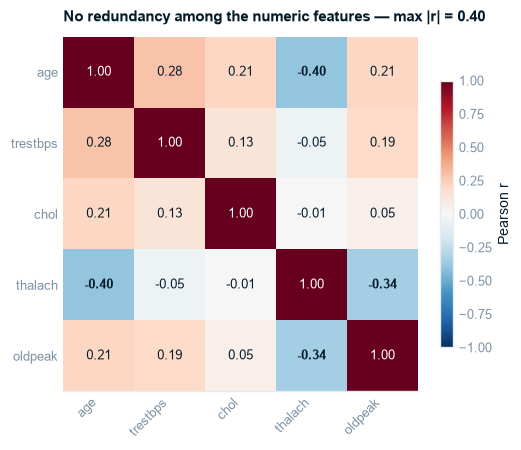

strongest off-diagonal pair:
  ('age', 'thalach')  r = -0.395


In [12]:
# Pearson correlation among the numeric features only - checking for redundancy before modelling
num_corr = df[NUMERIC].corr()
fig, ax = plt.subplots(figsize=(5.2, 4.2))
im = ax.imshow(num_corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC)), NUMERIC, rotation=45, ha="right")
ax.set_yticks(range(len(NUMERIC)), NUMERIC)
for i in range(len(NUMERIC)):
    for j in range(len(NUMERIC)):
        v = num_corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(v) > 0.55 else NAVY,
                fontweight="bold" if i != j and abs(v) > 0.3 else "normal")
ax.set_title("No redundancy among the numeric features — max |r| = 0.40")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson r")
plt.show()

print("strongest off-diagonal pair:")
off = num_corr.where(~np.eye(len(NUMERIC), dtype=bool)).abs().stack()
print(f"  {off.idxmax()}  r = {num_corr.stack()[off.idxmax()]:+.3f}")

> **So What:** unlike WDBC-style datasets, this one has **no collinearity problem** — the
> strongest numeric pair is `age`↔`thalach` at r = −0.40, which is physiology (maximum heart rate
> declines with age), not redundancy.
>
> **Implication:** no PCA block and no aggressive feature selection are needed. A regularised
> logistic regression's coefficients will be stable and directly interpretable — which supports
> using it as the primary model rather than a black box. The `age`↔`thalach` relationship does
> motivate testing an age-adjusted heart-rate feature (`hr_reserve`) in Stage 4.

## 3.7 Ghost deck — revised against what the data actually shows

`DOCS/STRUCTURE.md` Stage 3 requires the storyboard to be updated after EDA.

In [13]:
ghost = pd.DataFrame([
    {"exhibit": "EX 1", "status": "CONFIRMED + STRENGTHENED",
     "revision": "Duplication is not just present but structured and outcome-correlated - "
                 "distorted case weighting on top of leakage. Stronger than hypothesised."},
    {"exhibit": "EX 2", "status": "NEW - promoted",
     "revision": "Cohort composition earns its own exhibit: the inverted age effect proves the "
                 "referral filter, and the 32% female share sets up the fairness audit."},
    {"exhibit": "EX 3", "status": "CONFIRMED",
     "revision": "Branch D (exercise) leads as hypothesised: oldpeak d=-0.95, thalach d=+0.93."},
    {"exhibit": "EX 4", "status": "CONFIRMED + CORRECTED",
     "revision": "cp is the strongest pre-test signal (V=0.52). But the data notes' cp==0 "
                 "'highest-risk' claim is inverted in this file - feature redefined."},
    {"exhibit": "EX 5", "status": "CONFIRMED",
     "revision": "Branch C is a genuine null: chol p=0.16, fbs p=0.76. Promoted to a Key Line."},
    {"exhibit": "EX 6-7", "status": "DROPPED",
     "revision": "No collinearity to resolve (max |r| = 0.40), so the planned VIF/PCA exhibits "
                 "have nothing to show. Reported as one line in the appendix instead."},
    {"exhibit": "EX 8-11", "status": "PENDING",
     "revision": "Leakage experiment, scope comparison, operating point, fairness - Stage 5b/6."},
])
ghost

,exhibit,status,revision
0,EX 1,CONFIRMED + STRENGTHENED,Duplication is not just present but structured...
1,EX 2,NEW - promoted,Cohort composition earns its own exhibit: the ...
2,EX 3,CONFIRMED,Branch D (exercise) leads as hypothesised: old...
3,EX 4,CONFIRMED + CORRECTED,cp is the strongest pre-test signal (V=0.52). ...
4,EX 5,CONFIRMED,"Branch C is a genuine null: chol p=0.16, fbs p..."
5,EX 6-7,DROPPED,"No collinearity to resolve (max |r| = 0.40), s..."
6,EX 8-11,PENDING,"Leakage experiment, scope comparison, operatin..."


**Governing Thought, revised after EDA** (locked in Stage 7 once modelling lands):

> *This file's published accuracy is an artifact — 70% of its rows are copies, and its two
> strongest predictors come from the procedure that defines the label. On the 302 real patients,
> using only what a clinician knows before the catheter, the diagnostic signal is exercise
> response and symptom type — not the resting cholesterol and blood-pressure workup.*

### Data issues found in EDA and looped back (STRUCTURE.md Stage 3 → Stage 2)

| Issue | Resolution |
|---|---|
| `restecg` level 2 has n = 4 | Not fixed in cleaning — too small to merge without inventing a category. Carried to Stage 5a as a χ² expected-cell caveat and to Stage 4 as a one-hot stability note. |
| `oldpeak` 32% zero-inflation | Confirmed genuine (flat ST response), already logged in Stage 2. Model-selection consideration, not a data defect. |
| `cp` semantics unverifiable | Direction measured empirically; the data notes' label claim is not repeated. No cleaning change. |

No change to `heart_clean.parquet` was required — the Stage 2 → Stage 3 loop closed without a
second cleaning pass.

---

## Stage 3 — Gate Checklist

- [x] **Automated profiling generated and reviewed** — manual panel in §3.1 (pinned-deps
      equivalent); scale disparity, skew, zero-inflation and thin levels all identified.
- [x] **Each Stage 0 hypothesis has a corresponding analysis** — issue-tree branches A–E covered
      in §3.2 (A), §3.3 (A/C/D), §3.4 (B/D/E), §3.5 (C in full).
- [x] **Key distributions and relationships visualised and annotated** — Exhibits 2, 3, 4 plus
      the numeric correlation matrix.
- [x] **All chart titles are Action Titles** — every exhibit title states the insight.
- [x] **Every finding has a documented "So What" and "Implication"** — §3.2, §3.3, §3.4, §3.5, §3.6.
- [x] **Ghost deck updated** — §3.7: EX 2 promoted, EX 6–7 dropped, EX 4 corrected.
- [x] **Data issues logged and addressed** — three logged in §3.7; none required a second
      cleaning pass.
- [x] **Preliminary findings documented** — revised Governing Thought in §3.7.

**Next:** `04_diagnostic.ipynb` — Path A statistical verdicts with effect sizes, bootstrap
confidence intervals and FDR correction.